"""
**Atividade Prática - Desvendando APIs com Python e Dados de Saúde**
================================================================
**Fonte  : Portal da Transparência (api.portaldatransparencia.gov.br**)

**Dados  : Gastos do governo federal na função Saúde (código 10)**

***Requisitos atendidos:***
  1. Autenticação via token no cabeçalho (headers)         ✅
  2. Requisição com a biblioteca requests                  ✅

 3. Conversão da resposta para JSON                      ✅

  4. Conversão para DataFrame (pandas)                    ✅

  5. Limpeza e filtragem de dados                         ✅

  6. Plotagem de gráficos (matplotlib / seaborn)           ✅

---



In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import time
from google.colab import userdata

# ─────────────────────────────────────────────
# CONFIGURAÇÃO VISUAL DO PANDAS
# ─────────────────────────────────────────────
pd.options.display.float_format = '{:,.2f}'.format

# ─────────────────────────────────────────────
# 1. AUTENTICAÇÃO E CONFIGURAÇÃO
# ─────────────────────────────────────────────
try:
    API_TOKEN = userdata.get("PORTAL_TRANSPARENCIA_TOKEN")
    print("🔑 Token carregado com sucesso dos Segredos do Colab.")
except userdata.SecretNotFoundError:
    print("❌ Erro: O segredo 'PORTAL_TRANSPARENCIA_TOKEN' não foi encontrado.")
    API_TOKEN = None

if API_TOKEN
    HEADERS = {
        "chave-api-dados": API_TOKEN,
        "Accept": "application/json, text/plain, */*",
        "Accept-Language": "pt-BR,pt;q=0.9,en-US;q=0.8,en;q=0.7",
        "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36"
    }
    BASE_URL = "https://api.portaldatransparencia.gov.br/api-de-dados"

🔑 Token carregado com sucesso dos Segredos do Colab.


In [ ]:
# ─────────────────────────────────────────────
# 2. FUNÇÕES BASE (Agora com os gráficos incluídos!)
# ─────────────────────────────────────────────
def buscar_gastos_saude(ano: int, pagina: int = 1) -> list[dict]:
    # Endpoint por órgão (25000 = Ministério da Saúde) para maior estabilidade
    endpoint = f"{BASE_URL}/despesas/por-orgao"
    params = {"ano": ano, "orgaoSuperior": "25000", "pagina": pagina}

    resposta = requests.get(endpoint, headers=HEADERS, params=params, timeout=30)
    resposta.raise_for_status()
    return resposta.json()

def buscar_todas_paginas(ano: int) -> list[dict]:
    todos_os_dados: list[dict] = []
    pagina = 1
    print(f"\n📡 Ligando à API do Portal da Transparência — ano {ano}...")

    while True:
        dados = buscar_gastos_saude(ano, pagina)
        if not dados:
            break
        todos_os_dados.extend(dados)
        print(f"   Página {pagina} → {len(dados)} registos recebidos")
        pagina += 1
        time.sleep(1) # Pausa de segurança para evitar bloqueio por excesso de pedidos

        if pagina > 5:
            break

    print(f"✅ Total de registos coletados: {len(todos_os_dados)}")
    return todos_os_dados

def processar_dados(registros: list[dict]) -> tuple[pd.DataFrame, str | None]:
    df = pd.DataFrame(registros)

    # Identifica colunas de valores financeiros
    colunas_valor = [c for c in df.columns if any(t in c.lower() for t in ["valor", "empenha", "pago"])]

    for col in colunas_valor:
        df[col] = (df[col].astype(str)
                   .str.replace(".", "", regex=False)
                   .str.replace(",", ".", regex=False)
                   .pipe(pd.to_numeric, errors="coerce"))

    col_principal = colunas_valor[0] if colunas_valor else None
    if col_principal:
        df = df[df[col_principal] > 0].copy()

    return df, col_principal
def plotar_resultados(df: pd.DataFrame, col_valor: str, ano: int):
    sns.set_theme(style="whitegrid", palette="muted")
    # Cria a figura e guarda na variável 'fig'
    fig, axes = plt.subplots(1, 3, figsize=(24, 7))
    fig.suptitle(f"Análise de Gastos: Ministério da Saúde — {ano}", fontsize=18, fontweight="bold")

    # ─── Gráfico 1: Top Órgãos (Barras) ───
    top_orgaos = df.groupby("orgao")[col_valor].sum().nlargest(10).reset_index()
    top_orgaos["orgao"] = top_orgaos["orgao"].apply(lambda x: str(x)[:35] + "..." if len(str(x)) > 35 else str(x))

    sns.barplot(data=top_orgaos, x=col_valor, y="orgao", ax=axes[0], color="#4C72B0")
    axes[0].set_title("Top Órgãos (Valor Empenhado)")
    axes[0].set_ylabel("")
    axes[0].set_xlabel("Valor Empenhado (R$)")
    axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R${x/1e9:.1f}B"))

    # ─── Gráfico 2: Distribuição (Histograma) ───
    axes[1].hist(df[col_valor].dropna(), bins=15, color="#5B9BD5", edgecolor="black")
    axes[1].set_title("Distribuição dos Valores")
    axes[1].set_xlabel("Valor (R$)")
    axes[1].set_ylabel("Frequência")
    axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R${x/1e9:.1f}B"))

    # ─── Gráfico 3: Participação (Pizza com Legenda Externa) ───
    top5 = df.groupby("orgao")[col_valor].sum().nlargest(5)

    wedges, texts = axes[2].pie(
        top5,
        startangle=140,
        colors=sns.color_palette("Pastel1")
    )
    axes[2].set_title("Participação dos 5 Maiores")

    total_top5 = top5.sum()
    legendas = []
    for orgao, valor in top5.items():
        porcentagem = (valor / total_top5) * 100
        nome_curto = str(orgao)[:30] + "..." if len(str(orgao)) > 30 else str(orgao)
        legendas.append(f"{nome_curto} ({porcentagem:.1f}%)")

    axes[2].legend(
        wedges,
        legendas,
        title="Órgãos",
        loc="center left",
        bbox_to_anchor=(1, 0.5)
    )

    # Ajusta o layout usando a variável 'fig'
    fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    # Em vez de plt.savefig, usamos fig.savefig para salvar EXATAMENTE este gráfico
    nome_arquivo = f"gastos_saude_{ano}.png"
    fig.savefig(nome_arquivo, dpi=150, bbox_inches="tight", facecolor='white')
    print(f"\n📊 Imagem gerada e salva com sucesso: {nome_arquivo}")

    # Mostra na tela no final
    plt.show()


📡 Ligando à API do Portal da Transparência — ano 2024...
   Página 1 → 8 registos recebidos
✅ Total de registos coletados: 8

👀 ESPIANDO A TABELA ANTES DE SALVAR:


,ano,orgao,codigoOrgao,orgaoSuperior,codigoOrgaoSuperior,empenhado,liquidado,pago
0,2024,Ministério da Fazenda - Unidades com vínculo d...,25000,Ministério da Fazenda,25000,"2,496,340,598,608.96","2.452.178.155.051,67","2,451,509,464,328.55"
1,2024,Fundo Constitucional do Distrito Federal,25915,Ministério da Fazenda,25000,"23,371,555,913.88","22.798.917.997,41","22,219,693,002.45"
2,2024,Receita Federal do Brasil,25801,Ministério da Fazenda,25000,"2,149,636,443.03","1.886.251.413,93","1,675,370,747.38"
3,2024,Fundo de Garantia à Exportação,25914,Ministério da Fazenda,25000,"956,436,109.46","944.678.653,42","944,678,653.42"
4,2024,Superintendência de Seguros Privados,25208,Ministério da Fazenda,25000,"260,341,098.70","255.305.387,09","237,185,448.30"



💰 Total Empenhado: R$ 2,523,895,980,607.37

📊 OLHANDO OS GRÁFICOS:

📊 Imagem gerada e salva com sucesso: gastos_saude_2024.png


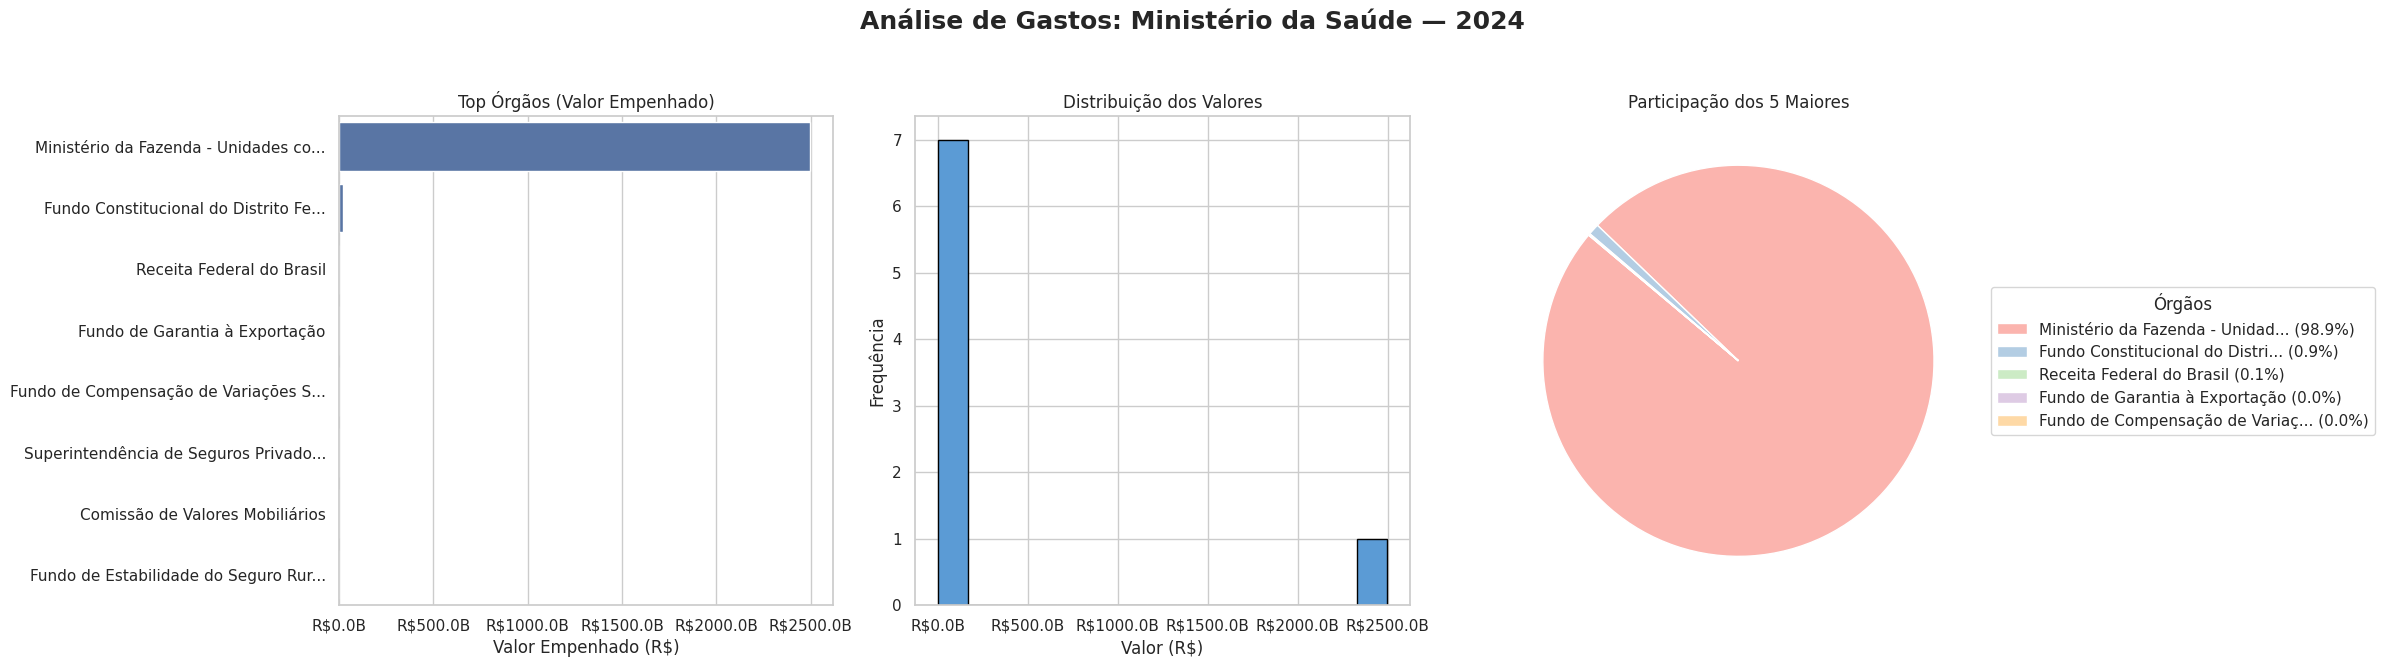

In [ ]:
ANO = 2024

if API_TOKEN:
    registros_brutos = buscar_todas_paginas(ANO)

    if registros_brutos:
        df_final, col_analise = processar_dados(registros_brutos)

        print("\n👀 ESPIANDO A TABELA ANTES DE SALVAR:")
        display(df_final.head()) # Isso vai gerar uma tabela no Colab

        print(f"\nTotal Empenhado: R$ {df_final[col_analise].sum():,.2f}\n")

        print("📊 OLHANDO OS GRÁFICOS:")
        plotar_resultados(df_final, col_analise, ANO)

In [ ]:
if API_TOKEN and registros_brutos:
    # Exportação final do CSV e da Imagem
    nome_csv = f"gastos_saude_{ANO}.csv"
    df_final.to_csv(nome_csv, index=False, encoding="utf-8-sig")

    # Salva a imagem (A função plotar_resultados já abriu na tela, mas agora salvamos no disco)
    plt.savefig(f"gastos_saude_{ANO}.png", dpi=150)

    print(f"✅ SUCESSO! Ficheiros '{nome_csv}' e 'gastos_saude_{ANO}.png' gerados!")
    print("👉 Abra a aba de 'Arquivos' (ícone de pasta) na esquerda do Colab para baixar.")

✅ SUCESSO! Ficheiros 'gastos_saude_2024.csv' e 'gastos_saude_2024.png' gerados!
👉 Abra a aba de 'Arquivos' (ícone de pasta) na esquerda do Colab para baixar.


<Figure size 640x480 with 0 Axes>